# Лабораторная работа 4-Бонус

## Проверка данных на нормальность (Iris)

**ФИО:** Аюпова В.Р.
**Группа:** ЕТ-212
**Дата:** 04.11.2026

## Пункты 1–4. Загрузка и подготовка данных

**Условие:**
1. Загрузить `Iris.xlsx` в DataFrame.
2. Удалить столбцы с номером сорта и названием сорта.
3. Заменить названия столбцов русскими переводами (petal/sepal, length/width).
4. Присвоить строкам индексы 1, 2, ..., 150.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

%matplotlib inline
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["font.size"] = 11

os.makedirs("images", exist_ok=True)

In [4]:
# 1. Загрузка данных
df_iris = pd.read_excel("data/Iris.xlsx", sheet_name="Data")
print("Исходные столбцы:", df_iris.columns.tolist())

# 2. Удаление столбцов с номером и названием сорта
df_iris = df_iris.drop(columns=["Species_No", "Species_name"])

# 3. Переименование столбцов на русский
df_iris = df_iris.rename(columns={
    "Petal_length": "длина лепестка",
    "Petal_width": "ширина лепестка",
    "Sepal_length": "длина чашелистика",
    "Sepal_width": "ширина чашелистика"
})

# Меняем порядок столбцов для красоты (как в задании: petal, sepal)
df_iris = df_iris[["длина лепестка", "ширина лепестка", "длина чашелистика", "ширина чашелистика"]]

# 4. Присвоение индексов 1..150
df_iris.index = range(1, len(df_iris) + 1)

print("\nСтолбцы после обработки:", df_iris.columns.tolist())
df_iris.head()

Исходные столбцы: ['Species_No', 'Petal_width', 'Petal_length', 'Sepal_width', 'Sepal_length', 'Species_name']

Столбцы после обработки: ['длина лепестка', 'ширина лепестка', 'длина чашелистика', 'ширина чашелистика']


,длина лепестка,ширина лепестка,длина чашелистика,ширина чашелистика
1,1.4,0.2,5.1,3.5
2,1.4,0.2,4.9,3.0
3,1.3,0.2,4.7,3.2
4,1.5,0.2,4.6,3.1
5,1.4,0.2,5.0,3.6


## Пункт 5. Функция `Gauss`

**Условие:** Создать функцию, которая комплексно проверяет выборку на нормальность (печатает объём выборки, строит гистограмму/KDE, находит среднее/медиану, асимметрию/эксцесс, формулирует гипотезы, запускает хи-квадрат Пирсона и делает вывод при α=0.05).

In [8]:
def Gauss(series, name="показатель", alpha=0.05):
    """Комплексная проверка одномерной выборки на нормальность."""
    data = series.dropna()
    n = len(data)

    print(f"=== Проверка на нормальность: {name} ===")
    print(f"Объём выборки: n = {n}")

    # b. гистограмма + kde
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.histplot(data, kde=True, bins=15, ax=ax, color="steelblue", edgecolor="black")
    ax.axvline(data.mean(), color="red", linestyle="--", label=f"Среднее = {data.mean():.2f}")
    ax.axvline(data.median(), color="green", linestyle="--", label=f"Медиана = {data.median():.2f}")
    ax.set_title(f"Распределение: {name}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # c. среднее и медиана
    print(f"Среднее: {data.mean():.4f}, Медиана: {data.median():.4f} (разница: {abs(data.mean() - data.median()):.4f})")

    # d. асимметрия и эксцесс
    print(f"Асимметрия: {stats.skew(data):.4f}, Эксцесс: {stats.kurtosis(data):.4f}")

    # e. гипотезы
    print("H0: данные распределены нормально (по Гауссу)")
    print("H1: данные НЕ распределены нормально")

    # f. критерий хи-квадрат Пирсона по сгруппированным частотам
    observed, bin_edges = np.histogram(data, bins="auto")
    cdf_vals = stats.norm.cdf(bin_edges, loc=data.mean(), scale=data.std(ddof=1))
    expected = np.diff(cdf_vals) * n

    # объединяем бины, где ожидаемая частота < 5
    obs_f, exp_f = [], []
    obs_acc, exp_acc = 0.0, 0.0
    for o, e in zip(observed, expected):
        obs_acc += o
        exp_acc += e
        if exp_acc >= 5:
            obs_f.append(obs_acc)
            exp_f.append(exp_acc)
            obs_acc, exp_acc = 0.0, 0.0
    if exp_acc > 0:
        if obs_f:
            obs_f[-1] += obs_acc
            exp_f[-1] += exp_acc
        else:
            obs_f.append(obs_acc)
            exp_f.append(exp_acc)

    # Нормировка
    obs_f = np.array(obs_f, dtype=float)
    exp_f = np.array(exp_f, dtype=float)
    exp_f = exp_f * (obs_f.sum() / exp_f.sum())

    chi2_stat, p_value = stats.chisquare(f_obs=obs_f, f_exp=exp_f)

    # g. печать статистики и p-value
    print(f"Критерий хи-квадрат: stat = {chi2_stat:.4f}, p-value = {p_value:.6f}")

    # h. вывод
    print(f"Уровень значимости α = {alpha}")
    if p_value < alpha:
        print("p-value < α → H0 отвергается. Данные НЕ распределены нормально.")
    else:
        print("p-value ≥ α → H0 не отвергается. Данные распределены нормально.")
    print("=" * 50)
    
    return p_value

## Пункт 6. Проверка всех 4 показателей

**Условие:** Проверить все показатели цветков на нормальность, сопровождая вызов печатью названия показателя.

=== Проверка на нормальность: длина лепестка ===
Объём выборки: n = 150


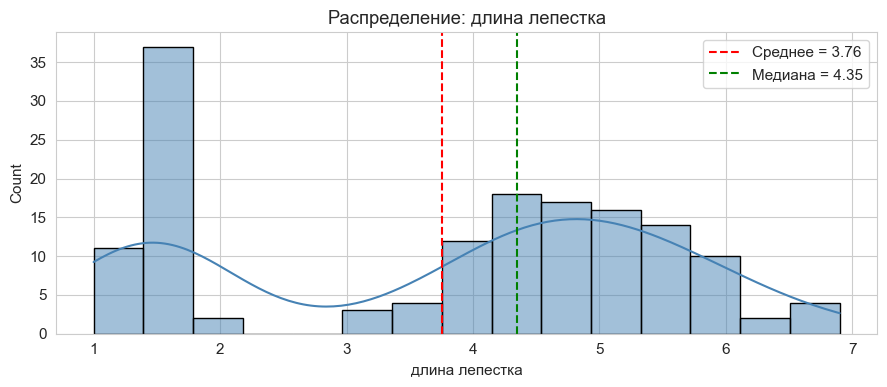

Среднее: 3.7580, Медиана: 4.3500 (разница: 0.5920)
Асимметрия: -0.2721, Эксцесс: -1.3955
H0: данные распределены нормально (по Гауссу)
H1: данные НЕ распределены нормально
Критерий хи-квадрат: stat = 173.7158, p-value = 0.000000
Уровень значимости α = 0.05
p-value < α → H0 отвергается. Данные НЕ распределены нормально.
=== Проверка на нормальность: ширина лепестка ===
Объём выборки: n = 150


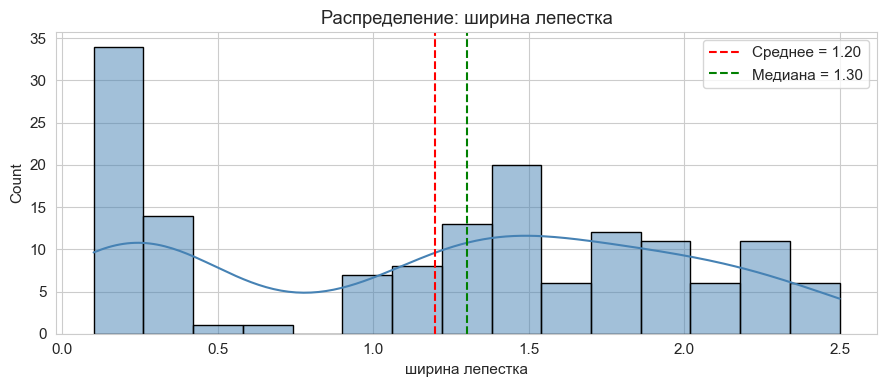

Среднее: 1.1993, Медиана: 1.3000 (разница: 0.1007)
Асимметрия: -0.1019, Эксцесс: -1.3361
H0: данные распределены нормально (по Гауссу)
H1: данные НЕ распределены нормально
Критерий хи-квадрат: stat = 123.9775, p-value = 0.000000
Уровень значимости α = 0.05
p-value < α → H0 отвергается. Данные НЕ распределены нормально.
=== Проверка на нормальность: длина чашелистика ===
Объём выборки: n = 150


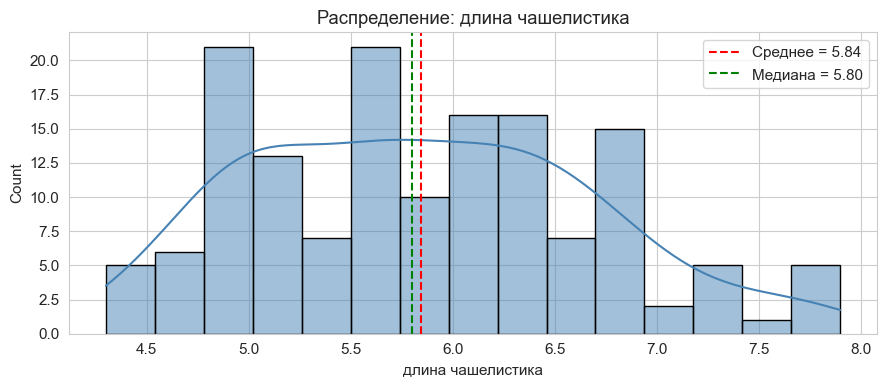

Среднее: 5.8433, Медиана: 5.8000 (разница: 0.0433)
Асимметрия: 0.3118, Эксцесс: -0.5736
H0: данные распределены нормально (по Гауссу)
H1: данные НЕ распределены нормально
Критерий хи-квадрат: stat = 8.4028, p-value = 0.298420
Уровень значимости α = 0.05
p-value ≥ α → H0 не отвергается. Данные распределены нормально.
=== Проверка на нормальность: ширина чашелистика ===
Объём выборки: n = 150


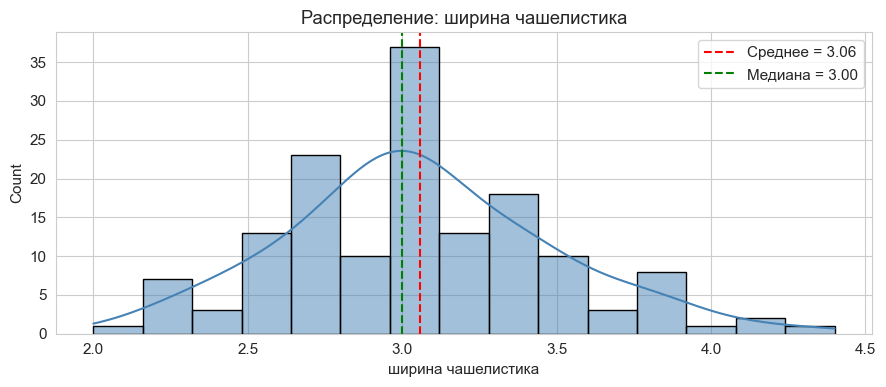

Среднее: 3.0573, Медиана: 3.0000 (разница: 0.0573)
Асимметрия: 0.3158, Эксцесс: 0.1810
H0: данные распределены нормально (по Гауссу)
H1: данные НЕ распределены нормально
Критерий хи-квадрат: stat = 12.4388, p-value = 0.189688
Уровень значимости α = 0.05
p-value ≥ α → H0 не отвергается. Данные распределены нормально.


In [6]:
p_values = {}
for col in df_iris.columns:
    p_values[col] = Gauss(df_iris[col], name=col)